<a href="https://colab.research.google.com/github/xtianu/Docencia/blob/main/UPC/DAPR/S4.%20Flipped%20classroom/S4_FlippedClassroom_Exercises_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


### My Answers

1. You need to explicitly set the number of clusters in k-means, whereas it does not need to be set in hierarchical clustering--you can just cut the dendogram where you wish.
2. k-means treats all data points equally, so it is very sensitive to outliers, and uses Euclidean distance to assign points to the nearest centroid, which inherently assumes that the clusters are spherical and of similar sizes and densities. Since it tries to minimize the within-cluster sum of square distances between points, it gives more weight to larger clusters and prefers splitting them up. 
3. The Bayesian Information Criterion (BIC) in GMM is used to determine the optimal number of components (like clusters) in the mixture. It is an equation that balances the number of free parameters against the model's complexity to avoid overfitting. 

This notebook is available in a fork of the original course Github repository: https://github.com/laetichou/UPC_DAPR_2026.git 

---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values per column:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Data is clean, no missing values.


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.418347,-0.564142
1,-0.811126,0.126188,-1.062250,-0.501703
2,-0.664380,0.430462,-0.421277,-1.188532
4,-1.324737,1.089724,-0.563715,-0.938776
5,-0.847812,1.748985,-0.777373,-0.689020


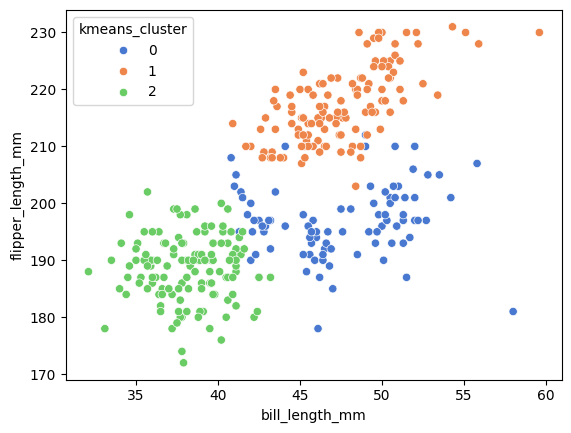

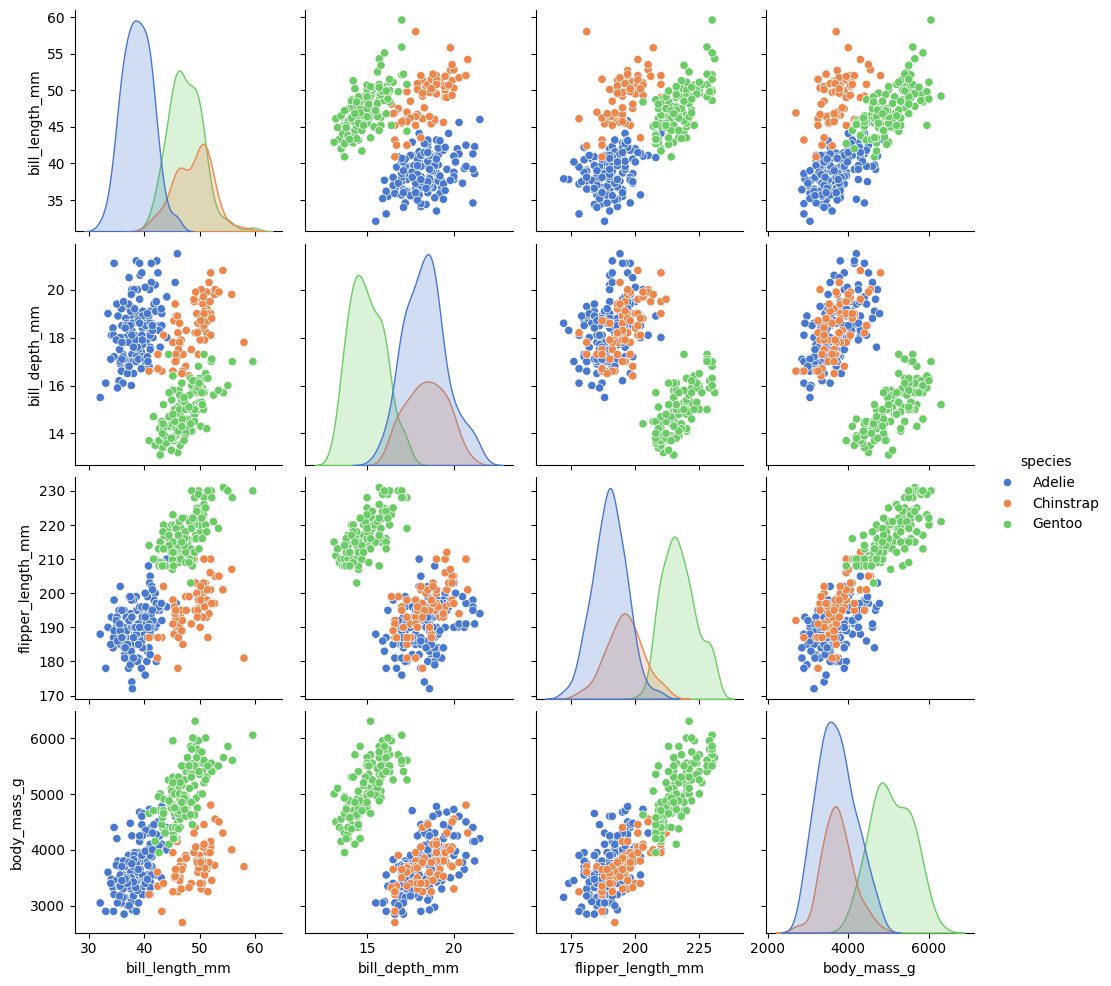

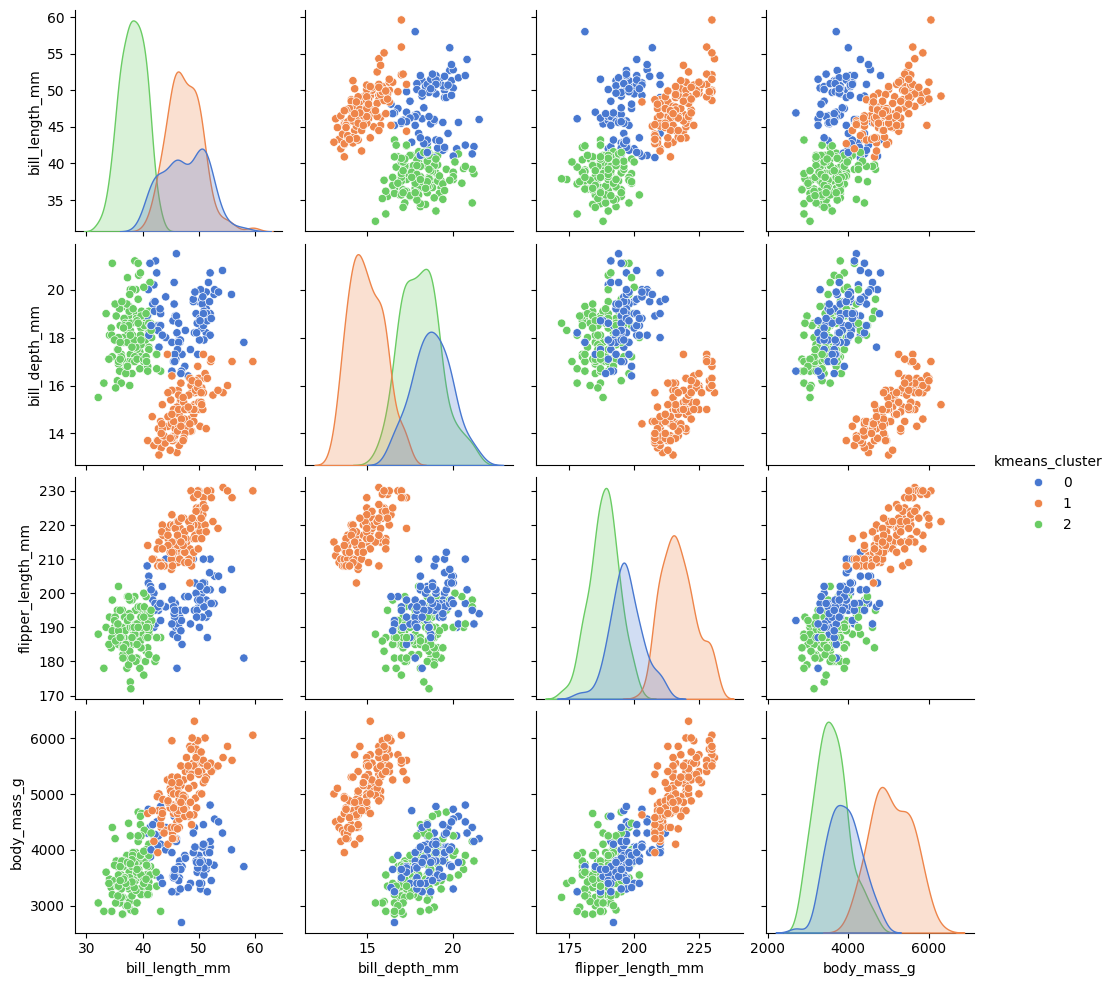

,Cluster 0,Cluster 1,Cluster 2
Adelie,24,0,127
Chinstrap,63,0,5
Gentoo,0,123,0


Adjusted Rand score: 0.793
('The confusion matrix shows how the KMeans clusters correspond to the actual '
 'species of penguins.Each row represents the true species, while each column '
 'represents the predicted cluster.We can see that the KMeans clustering '
 'correctly clustered all the Gentoo together,and nearly all the Adelie '
 'together, but the Chinstrap is mixed with the rest of the Adelie '
 'penguins.The adjusted Rand score of 0.793 indicates that the clustering is '
 'pretty good, but not perfect.')


In [41]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
penguins_num = penguins[num_cols]
print("Missing values per column:")
print(penguins_num.isnull().sum())

penguins_clean = penguins_num.dropna()
if penguins_clean.isnull().sum().sum() == 0:  # First .sum() sums per column, second .sum() sums across all columns
    print()
    print("Data is clean, no missing values.")

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
scaler = StandardScaler()
penguins_scaled_df = pd.DataFrame(
    scaler.fit_transform(penguins_clean),
    columns=penguins_clean.columns,
    index=penguins_clean.index
)

display(penguins_scaled_df.head())

# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans_labels = KMeans(n_clusters=3, random_state=42).fit_predict(penguins_scaled_df)

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)

penguins_plot = penguins.loc[penguins_clean.index, num_cols + ["species"]].copy()  # select only rows without missing values and keep species column
penguins_plot["kmeans_cluster"] = kmeans_labels

# Scatterplot: two features, colored by cluster
sns.scatterplot(
    data=penguins_plot,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="kmeans_cluster",
    palette="muted",
)
plt.show()

# Pairplot colored by actual species
sns.pairplot(data=penguins_plot, vars=num_cols, hue="species", palette="muted")
plt.show()
    # diagonal shows kernel density estimate plots for each feature,
    # off-diagonal shows scatterplots of each pair of features. 
    # The points are colored by species: see how well the species are separated in the feature space.

# Pairplot colored by KMeans cluster
sns.pairplot(data=penguins_plot, vars=num_cols, hue="kmeans_cluster", palette="muted")
plt.show()


# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'
species_true = penguins.loc[penguins_clean.index, "species"]  # pandas series containing the true species labels for the rows without missing values

species_encoder = LabelEncoder()  # label between 0 and n_classes-1 for each species
species_encoded = species_encoder.fit_transform(species_true)

cm = confusion_matrix(species_encoded, kmeans_labels)
cm_df = pd.DataFrame(
    cm,
    index=species_encoder.classes_,
    columns=[f"Cluster {label}" for label in sorted(set(kmeans_labels))]
)
display(cm_df)

ari = adjusted_rand_score(species_true, kmeans_labels)
print(f"Adjusted Rand score: {ari:.3f}")  # 1.0 is a perfect match, 0.0 is random labeling, negative values indicate worse than random

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation
pprint("The confusion matrix shows how the KMeans clusters correspond to the actual species of penguins." \
        "Each row represents the true species, while each column represents the predicted cluster." \
        "We can see that the KMeans clustering correctly clustered all the Gentoo together," \
        "and nearly all the Adelie together, but the Chinstrap is mixed with the rest of the Adelie penguins." \
        f"The adjusted Rand score of {ari:.3f} indicates that the clustering is pretty good, but not perfect."\
)


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

In [20]:
%pip install numpy scipy

5.656854249492381
5.656854249492381
The euclidean_distance function works correctly.


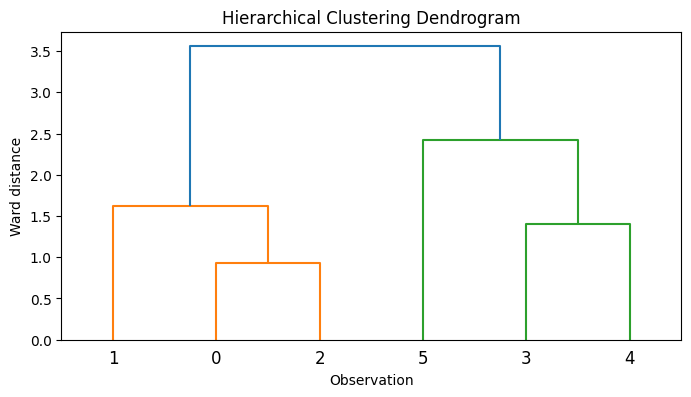

Agglomerative labels: [1 1 1 0 0 0]
K-means labels: [0 0 0 1 1 1]


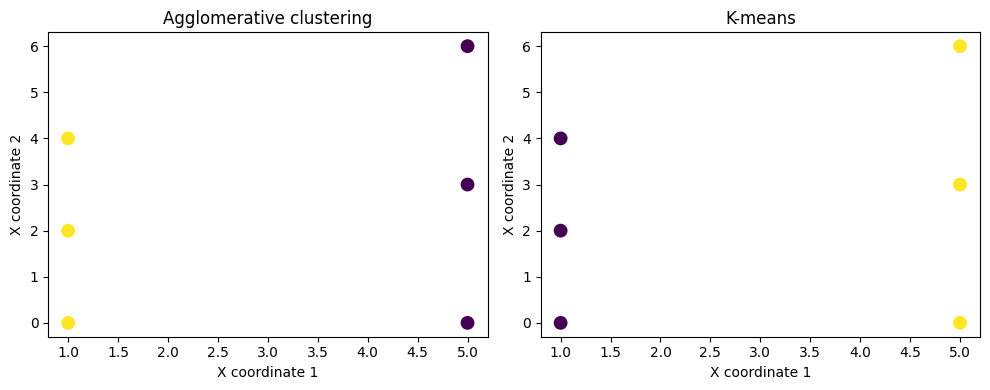

Agglomerative cluster sizes: {1: 3, 0: 3}
K-means cluster sizes: {0: 3, 1: 3}


In [28]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
if np.isnan(X).any():
    print("There are missing values in X.")

# b) YOUR CODE HERE: normalize X with StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):  # Where p1 and p2 coordinates of two points in the same n-dimensional space
    sum_squared_diff = 0
    for i in range(len(p1)):
        # calculate the squared difference for each dimension
        sum_squared_diff += (p1[i] - p2[i]) ** 2
    # sum the squared differences and take the square root
    distance = sum_squared_diff ** 0.5
    return distance

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))
if euclidean_distance(X[0], X[3]) == np.linalg.norm(X[0] - X[3]):
    print("The euclidean_distance function works correctly.")

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram

agglo_clustering = AgglomerativeClustering(compute_full_tree='auto',
            linkage='ward', n_clusters=2).fit(X)
agglo_labels = agglo_clustering.fit_predict(X_scaled)
# print(agglo_labels)

# Dendrogram from the normalized data
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(8, 4))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Ward distance")
plt.show()


# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print("Agglomerative labels:", agglo_labels)
print("K-means labels:", kmeans_labels)

# scatterplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, cmap="viridis", s=80)
axes[0].set_title("Agglomerative clustering")

axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="viridis", s=80)
axes[1].set_title("K-means")

for axis in axes:
    axis.set_xlabel("X coordinate 1")
    axis.set_ylabel("X coordinate 2")

plt.tight_layout()
plt.show()

# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
    sizes = {}
    for label in labels:
        if label in sizes:
            sizes[int(label)] += 1
        else:
            sizes[int(label)] = 1
    return sizes

print("Agglomerative cluster sizes:", cluster_sizes(agglo_labels))
print("K-means cluster sizes:", cluster_sizes(kmeans_labels))


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Number of missing values per column: carat    0
depth    0
table    0
price    0
dtype: int64
Diamonds data is clean, no missing values.


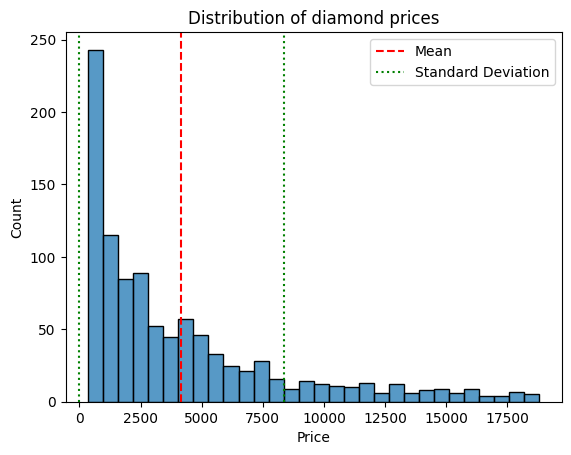

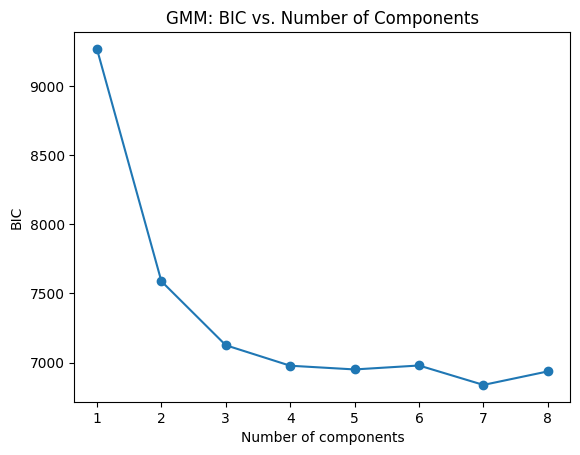

Best number of components according to BIC: 7


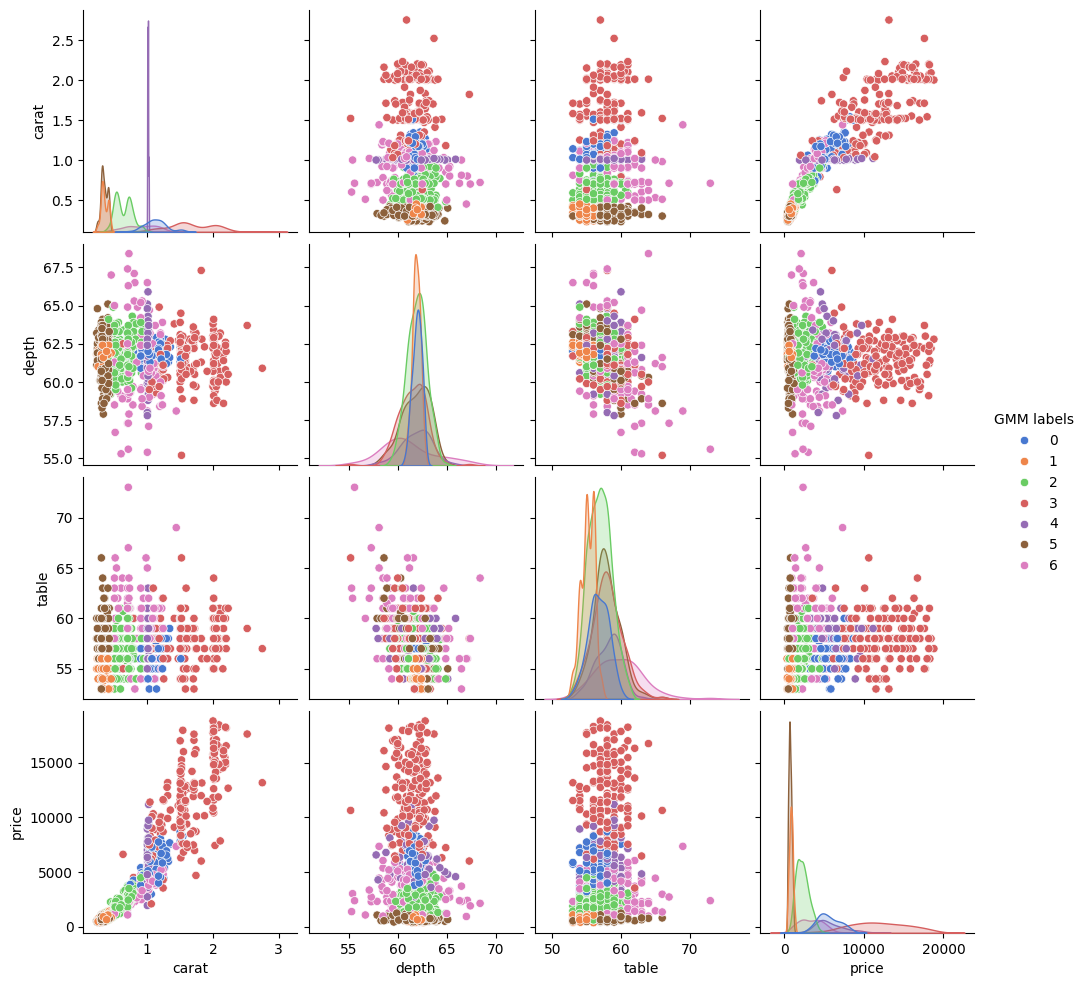

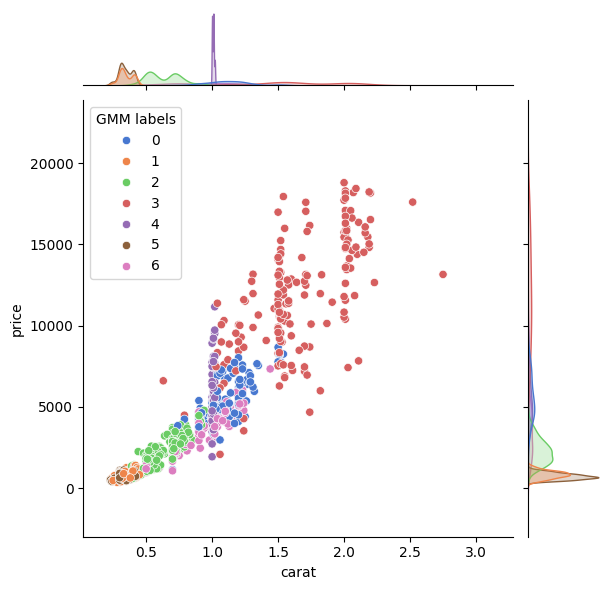

In [ ]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
num_cols = ["carat", "depth", "table", "price"]
diamonds_num = diamonds[num_cols]
print("Number of missing values per column:", diamonds_num.isnull().sum())
diamonds_num = diamonds_num.dropna()
if diamonds_num.isnull().sum().sum() == 0:
    print("Diamonds data is clean, no missing values.")

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
price_mean = diamonds_num["price"].mean()
price_std = diamonds_num["price"].std()

sns.histplot(data=diamonds_num, x="price", bins=30)  # 30 bins for 1000 samples, makes sense

plt.axvline(price_mean, color="red", linestyle="--", label="Mean")
plt.axvline(price_mean - price_std, color="green", linestyle=":", label="Standard Deviation")
plt.axvline(price_mean + price_std, color="green", linestyle=":", label="_nolegend_")  # _nolegend_ to avoid duplicate legend entry

plt.xlabel("Price")
plt.title("Distribution of diamond prices")
plt.legend()
plt.show()

# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num)

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

for n_components in n_components_range:
    gmm = mixture.GaussianMixture(
        n_components=n_components,
        random_state=42,
        n_init=5  # multiple initializations to avoid local minima
    )
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))

plt.plot(list(n_components_range), bic, marker="o")
plt.xlabel("Number of components")
plt.ylabel("BIC")
plt.title("GMM: BIC vs. Number of Components")
plt.xticks(list(n_components_range))
plt.show()

# print(min(bic))

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
best_n = bic.index(min(bic)) + 1  # +1 because index starts at 0
print(f"Best number of components according to BIC: {best_n}")

gmm_best = mixture.GaussianMixture(n_components=best_n, random_state=42, n_init=5)
gmm_labels = gmm_best.fit_predict(diamonds_scaled)

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
diamonds_num["GMM labels"] = gmm_labels  # add the GMM labels to the original (unscaled) dataframe

sns.pairplot(data=diamonds_num, vars=num_cols, hue="GMM labels", palette="muted")
plt.show()

sns.jointplot(data=diamonds_num, x="carat", y="price", hue="GMM labels", palette="muted")

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation

# As markdown below this cell.


#### g) Interpretation

The pairwise GMM plot looks messy and difficult to interpret, as the clusters are not well separated and there is a lot of overlap. This suggests that 7 clusters was not a reasonable estimate.
While the BIC suggests that 7 components is the best fit, in practice, it may not be meaningful. 
It is important to consider the interpretability of the clusters and whether they make sense in the context of the data. By looking at the data, I would have guessed 3 clusters (or maybe even 2, but that feels like too little). 

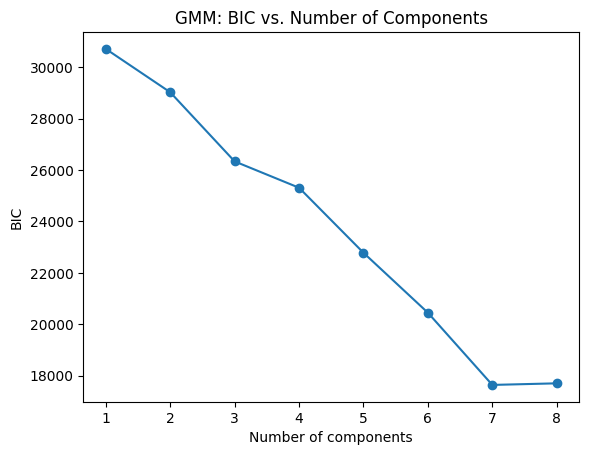

Best number of components according to BIC: 7


In [ ]:
# Testing GMM fit on unscaled diamonds data to see if it makes a difference
# make sure to run previous cell first to have diamonds_num and diamonds_scaled defined

bic_unscaled = []
n_components_range = range(1, 9)

for n_components in n_components_range:
    gmm = mixture.GaussianMixture(
        n_components=n_components,
        random_state=42,
        n_init=5  # multiple initializations to avoid local minima
    )
    gmm.fit(diamonds_num)  # fit on unscaled data
    bic_unscaled.append(gmm.bic(diamonds_num))

plt.plot(list(n_components_range), bic_unscaled, marker="o")
plt.xlabel("Number of components")
plt.ylabel("BIC")
plt.title("GMM: BIC vs. Number of Components")
plt.xticks(list(n_components_range))
plt.show()

best_n = bic_unscaled.index(min(bic_unscaled)) + 1  # +1 because index starts at 0
print(f"Best number of components according to BIC: {best_n}")

#### Answer
Surprisingly, it seems that normalizing the data did not change the optimal number of components found by BIC, as both scaled and unscaled data found 7. However, the optimal number of components on scaled data goes down much faster, such that when looking at the BIC vs. number of components plot for scaled data, any number of clusters above 3 already looks reasonable, whereas for the unscaled data, the BIC only starts to look reasonable at 7. 

We can then test the GMM at the number of components estimated by eye: 3.

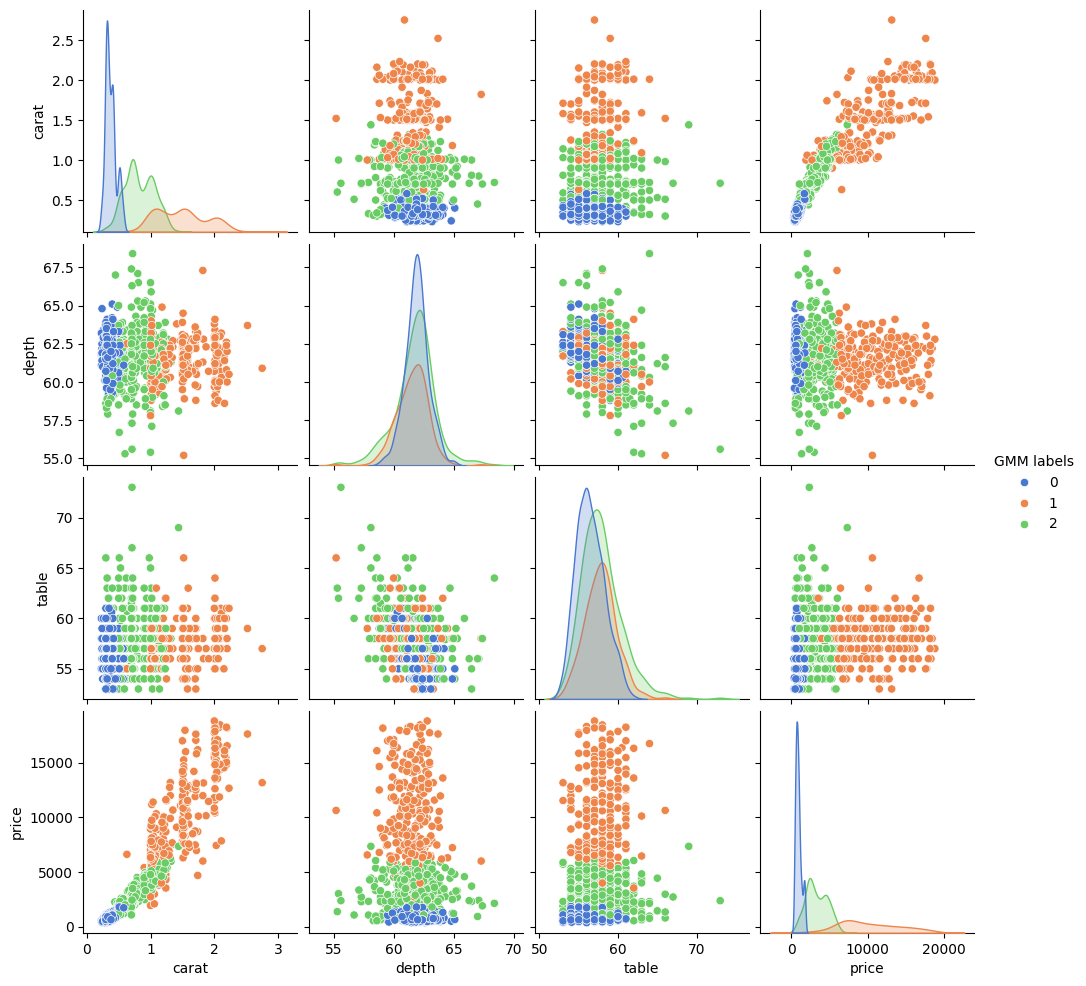

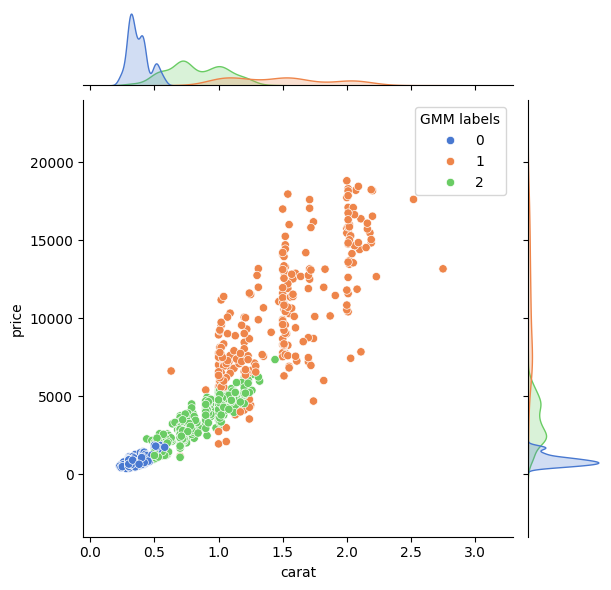

In [ ]:
gmm_3 = mixture.GaussianMixture(n_components=3, random_state=42, n_init=5)
gmm_labels = gmm_3.fit_predict(diamonds_scaled)  # fit 3 GMM clusters on scaled data

diamonds_num["GMM labels"] = gmm_labels  # add the GMM labels to the original (unscaled) dataframe

sns.pairplot(data=diamonds_num, vars=num_cols, hue="GMM labels", palette="muted")
plt.show()

sns.jointplot(data=diamonds_num, x="carat", y="price", hue="GMM labels", palette="muted")



I think 2 may even be better. 

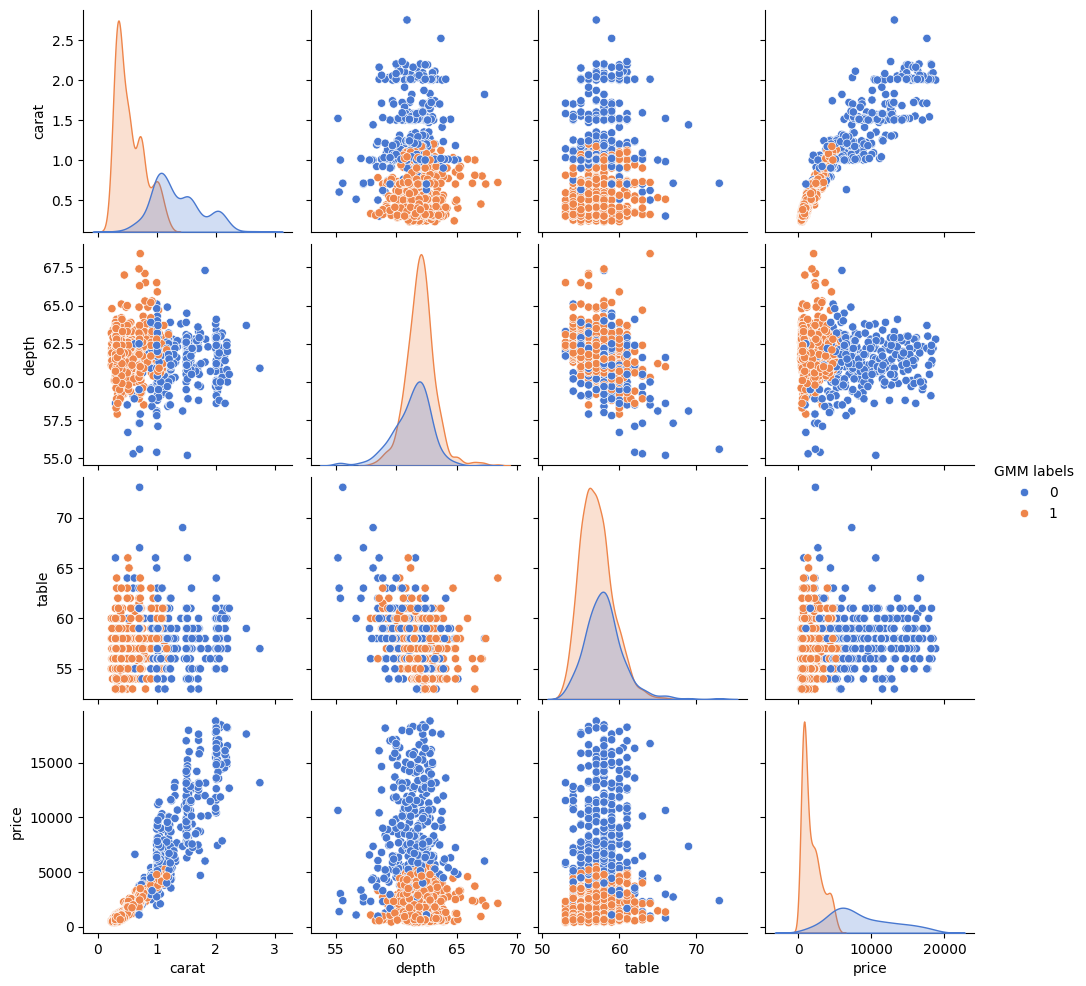

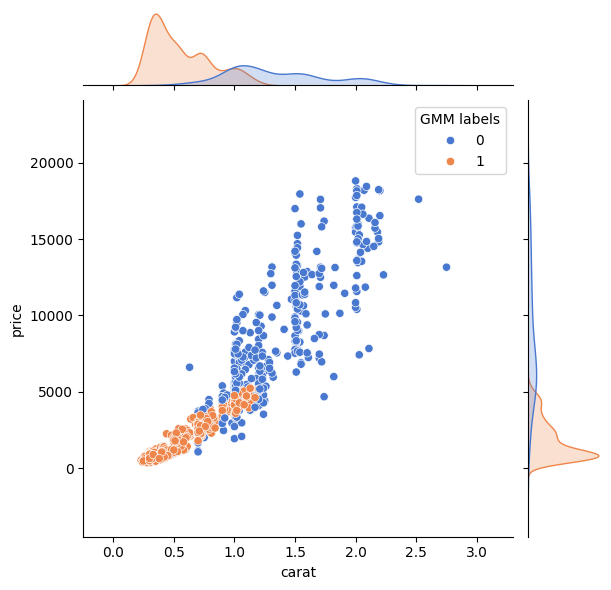

In [40]:
gmm_2 = mixture.GaussianMixture(n_components=2, random_state=42, n_init=5)
gmm_labels = gmm_2.fit_predict(diamonds_scaled)  # fit 3 GMM clusters on scaled data

diamonds_num["GMM labels"] = gmm_labels  # add the GMM labels to the original (unscaled) dataframe

sns.pairplot(data=diamonds_num, vars=num_cols, hue="GMM labels", palette="muted")
plt.show()

sns.jointplot(data=diamonds_num, x="carat", y="price", hue="GMM labels", palette="muted")

Nevermind I really don't know, I think 3 was better.